# Google playstore data
## Complete EDA analysis from begining to pro

#### Context
While many public datasets (on Kaggle and the like) provide Apple App Store data, there are not many counterpart datasets available for Google Play Store apps anywhere on the web. On digging deeper, I found out that iTunes App Store page deploys a nicely indexed appendix-like structure to allow for simple and easy web scraping. On the other hand, Google Play Store uses sophisticated modern-day techniques (like dynamic page load) using JQuery making scraping more challenging.

#### Content
Each app (row) has values for catergory, rating, size, and more.

#### Acknowledgements
This information is scraped from the Google Play Store. This app information would not be available without it.

# 1.Import all the libraries

In [166]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

# 2.Load the dataset and explore

- this is how we load a dataset


In [167]:
df = pd.read_csv('../data/googleplaystore.csv')

- setting maximum rows and columns

In [168]:
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)

- hide all the warnings

In [169]:
import warnings
warnings.filterwarnings('ignore')

- this is how we check the shape of the data

In [170]:
df.shape

(10841, 13)

- to check the columns of the data

In [171]:
df.columns

Index(['App', 'Category', 'Rating', 'Reviews', 'Size', 'Installs', 'Type',
       'Price', 'Content Rating', 'Genres', 'Last Updated', 'Current Ver',
       'Android Ver'],
      dtype='object')

- to print the number of rows

In [172]:
print("Number of rows:", df.shape[0], "Number of columns:", df.shape[1])

Number of rows: 10841 Number of columns: 13


- how to check the numeric data

In [173]:
df.describe()

,Rating
count,9367.000000
mean,4.193338
std,0.537431
min,1.000000
25%,4.000000
50%,4.300000
75%,4.500000
max,19.000000


- how to convert column into numeric data type

In [174]:
df['Size'].unique()
df['Size'].value_counts()
df.isnull().sum()
df['Size'].isnull().sum()

np.int64(0)

- We have no missing values in our (size) column

---
####  And we have 3 observation now
1.Varies with device  
2.M  
3.K  

----

- Now i will perform 3 functions

In [175]:
# find the number of vlaues which contains M in them
df['Size'].loc[df['Size'].str.contains('M')].count().sum()

np.int64(8829)

In [176]:
# Find the number of vlaues which contains K in them
df['Size'].loc[df['Size'].str.contains('k')].count().sum()

np.int64(316)

In [177]:
# Now i will find the values varies with device 
df['Size'].loc[df['Size'].str.contains('Varies with device')].count().sum()

np.int64(1695)

In [178]:
8829+316+1695

10840

In [179]:
len(df)

10841

In [180]:
df['Size'].loc[
    ~df['Size'].str.contains('K|M', case=False, na=False)
].value_counts()

Size
Varies with device    1695
1,000+                   1
Name: count, dtype: int64

- i convert the wholw size column into bytes


In [181]:
# first convert the whole size column into bytes
def convert_size(size):
    if isinstance(size, str):
        if 'M' in size:
            return float(size.replace('M', '')) * 1024 * 1024
        elif 'k' in size:
            return float(size.replace('k', '')) * 1024
        elif 'Varies with device' in size:
            return np.nan
    return size


In [182]:
df['Size']

0                       19M
1                       14M
2                      8.7M
3                       25M
4                      2.8M
5                      5.6M
6                       19M
7                       29M
8                       33M
9                      3.1M
10                      28M
11                      12M
12                      20M
13                      21M
14                      37M
15                     2.7M
16                     5.5M
17                      17M
18                      39M
19                      31M
20                      14M
21                      12M
22                     4.2M
23                     7.0M
24                      23M
25                     6.0M
26                      25M
27                     6.1M
28                     4.6M
29                     4.2M
30                     9.2M
31                     5.2M
32                      11M
33                      11M
34                     4.2M
35                  

In [183]:
# lets apply the function to the size column
df['Size'] = df['Size'].apply(convert_size)

In [184]:
df['Size']

0         19922944.0
1         14680064.0
2          9122611.2
3         26214400.0
4          2936012.8
5          5872025.6
6         19922944.0
7         30408704.0
8         34603008.0
9          3250585.6
10        29360128.0
11        12582912.0
12        20971520.0
13        22020096.0
14        38797312.0
15         2831155.2
16         5767168.0
17        17825792.0
18        40894464.0
19        32505856.0
20        14680064.0
21        12582912.0
22         4404019.2
23         7340032.0
24        24117248.0
25         6291456.0
26        26214400.0
27         6396313.6
28         4823449.6
29         4404019.2
30         9646899.2
31         5452595.2
32        11534336.0
33        11534336.0
34         4404019.2
35         9646899.2
36        25165824.0
37               NaN
38        11534336.0
39         9856614.4
40        15728640.0
41        10485760.0
42               NaN
43         1258291.2
44        12582912.0
45        25165824.0
46        27262976.0
47         83

In [185]:
df.head(10)

,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
0,Photo Editor & Candy Camera & Grid & ScrapBook,ART_AND_DESIGN,4.1,159,19922944.0,"10,000+",Free,0,Everyone,Art & Design,"January 7, 2018",1.0.0,4.0.3 and up
1,Coloring book moana,ART_AND_DESIGN,3.9,967,14680064.0,"500,000+",Free,0,Everyone,Art & Design;Pretend Play,"January 15, 2018",2.0.0,4.0.3 and up
2,"U Launcher Lite – FREE Live Cool Themes, Hide ...",ART_AND_DESIGN,4.7,87510,9122611.2,"5,000,000+",Free,0,Everyone,Art & Design,"August 1, 2018",1.2.4,4.0.3 and up
3,Sketch - Draw & Paint,ART_AND_DESIGN,4.5,215644,26214400.0,"50,000,000+",Free,0,Teen,Art & Design,"June 8, 2018",Varies with device,4.2 and up
4,Pixel Draw - Number Art Coloring Book,ART_AND_DESIGN,4.3,967,2936012.8,"100,000+",Free,0,Everyone,Art & Design;Creativity,"June 20, 2018",1.1,4.4 and up
5,Paper flowers instructions,ART_AND_DESIGN,4.4,167,5872025.6,"50,000+",Free,0,Everyone,Art & Design,"March 26, 2017",1.0,2.3 and up
6,Smoke Effect Photo Maker - Smoke Editor,ART_AND_DESIGN,3.8,178,19922944.0,"50,000+",Free,0,Everyone,Art & Design,"April 26, 2018",1.1,4.0.3 and up
7,Infinite Painter,ART_AND_DESIGN,4.1,36815,30408704.0,"1,000,000+",Free,0,Everyone,Art & Design,"June 14, 2018",6.1.61.1,4.2 and up
8,Garden Coloring Book,ART_AND_DESIGN,4.4,13791,34603008.0,"1,000,000+",Free,0,Everyone,Art & Design,"September 20, 2017",2.9.2,3.0 and up
9,Kids Paint Free - Drawing Fun,ART_AND_DESIGN,4.7,121,3250585.6,"10,000+",Free,0,Everyone,Art & Design;Creativity,"July 3, 2018",2.8,4.0.3 and up


In [186]:
# now i want to rename the column into size_in_bytes
df.rename(columns={'Size': 'Size_in_bytes'}, inplace=True)

In [187]:
df.rename(columns={'Size': 'Size_in_bytes'}, inplace=True)

print(df.columns)

Index(['App', 'Category', 'Rating', 'Reviews', 'Size_in_bytes', 'Installs',
       'Type', 'Price', 'Content Rating', 'Genres', 'Last Updated',
       'Current Ver', 'Android Ver'],
      dtype='object')


In [188]:
df.head(10)

,App,Category,Rating,Reviews,Size_in_bytes,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
0,Photo Editor & Candy Camera & Grid & ScrapBook,ART_AND_DESIGN,4.1,159,19922944.0,"10,000+",Free,0,Everyone,Art & Design,"January 7, 2018",1.0.0,4.0.3 and up
1,Coloring book moana,ART_AND_DESIGN,3.9,967,14680064.0,"500,000+",Free,0,Everyone,Art & Design;Pretend Play,"January 15, 2018",2.0.0,4.0.3 and up
2,"U Launcher Lite – FREE Live Cool Themes, Hide ...",ART_AND_DESIGN,4.7,87510,9122611.2,"5,000,000+",Free,0,Everyone,Art & Design,"August 1, 2018",1.2.4,4.0.3 and up
3,Sketch - Draw & Paint,ART_AND_DESIGN,4.5,215644,26214400.0,"50,000,000+",Free,0,Teen,Art & Design,"June 8, 2018",Varies with device,4.2 and up
4,Pixel Draw - Number Art Coloring Book,ART_AND_DESIGN,4.3,967,2936012.8,"100,000+",Free,0,Everyone,Art & Design;Creativity,"June 20, 2018",1.1,4.4 and up
5,Paper flowers instructions,ART_AND_DESIGN,4.4,167,5872025.6,"50,000+",Free,0,Everyone,Art & Design,"March 26, 2017",1.0,2.3 and up
6,Smoke Effect Photo Maker - Smoke Editor,ART_AND_DESIGN,3.8,178,19922944.0,"50,000+",Free,0,Everyone,Art & Design,"April 26, 2018",1.1,4.0.3 and up
7,Infinite Painter,ART_AND_DESIGN,4.1,36815,30408704.0,"1,000,000+",Free,0,Everyone,Art & Design,"June 14, 2018",6.1.61.1,4.2 and up
8,Garden Coloring Book,ART_AND_DESIGN,4.4,13791,34603008.0,"1,000,000+",Free,0,Everyone,Art & Design,"September 20, 2017",2.9.2,3.0 and up
9,Kids Paint Free - Drawing Fun,ART_AND_DESIGN,4.7,121,3250585.6,"10,000+",Free,0,Everyone,Art & Design;Creativity,"July 3, 2018",2.8,4.0.3 and up


### install column
- 1. remove the + sign from the install column
- 2. convert the install column into int
- 3. remove the commas from the install column (but the comma is already remove from my dataset )

In [189]:
df['Installs'].unique()

array(['10,000+', '500,000+', '5,000,000+', '50,000,000+', '100,000+',
       '50,000+', '1,000,000+', '10,000,000+', '5,000+', '100,000,000+',
       '1,000,000,000+', '1,000+', '500,000,000+', '50+', '100+', '500+',
       '10+', '1+', '5+', '0+', '0', 'Free'], dtype=object)

In [190]:
df['Installs'].value_counts()

Installs
1,000,000+        1579
10,000,000+       1252
100,000+          1169
10,000+           1054
1,000+             907
5,000,000+         752
100+               719
500,000+           539
50,000+            479
5,000+             477
100,000,000+       409
10+                386
500+               330
50,000,000+        289
50+                205
5+                  82
500,000,000+        72
1+                  67
1,000,000,000+      58
0+                  14
0                    1
Free                 1
Name: count, dtype: int64

In [191]:
# This is how we can clean the install column in pandas.
#  We can use the apply function to apply a lambda function to each value in the column. 
# The lambda function will check if the value is a string, and if it is,
#  it will remove the '+' sign and commas from the value.
#  If the value is not a string, it will return the value as is.

df['Installs'] = df['Installs'].apply(
    lambda x: x.replace('+', '').replace('+', '') if isinstance(x, str) else x
)

In [192]:
df['Installs'].value_counts()

Installs
1,000,000        1579
10,000,000       1252
100,000          1169
10,000           1054
1,000             907
5,000,000         752
100               719
500,000           539
50,000            479
5,000             477
100,000,000       409
10                386
500               330
50,000,000        289
50                205
5                  82
500,000,000        72
1                  67
1,000,000,000      58
0                  15
Free                1
Name: count, dtype: int64

### Price column

In [193]:
# now we will find how how many values have $ sign im the column
df['Price'].str.contains('$').sum()


np.int64(10841)

In [194]:
df['price']= df['Price'].apply(lambda x: x.replace('$', '') if '$' in str(x) else x)

In [195]:
df['Price'].str.contains('$').sum()

np.int64(10841)

In [196]:
df['price'].value_counts().sum()

np.int64(10841)

In [197]:
df['Price'] = df['Price'].replace('Everyone', '0')

In [198]:
df['price'].value_counts()

price
0           10040
0.99          148
2.99          129
1.99           73
4.99           72
3.99           63
1.49           46
5.99           30
2.49           26
9.99           21
6.99           13
399.99         12
14.99          11
4.49            9
3.49            7
29.99           7
7.99            7
24.99           7
5.49            6
19.99           6
12.99           5
6.49            5
8.99            5
11.99           5
2.00            3
10.00           3
16.99           3
1.00            3
7.49            2
17.99           2
8.49            2
10.99           2
79.99           2
9.00            2
39.99           2
1.70            2
3.95            2
13.99           2
33.99           2
15.99           1
1.50            1
400.00          1
74.99           1
25.99           1
3.88            1
4.84            1
1.76            1
3.02            1
4.77            1
1.59            1
2.50            1
1.29            1
1.61            1
5.00            1
299.99          1
37.9

In [199]:
df['Price'] = pd.to_numeric(df['Price'], errors='coerce')

print(df['Price'].dtype)
print(df['Price'].head())

float64
0    0.0
1    0.0
2    0.0
3    0.0
4    0.0
Name: Price, dtype: float64


In [200]:
# to find the minimum and maximum values in the price column we can use the min() function
df['Price'].min()
df['Price'].max()


np.float64(0.0)

In [201]:
 # find the missing valuesin the dataset 
df.isnull().sum()


App                  0
Category             0
Rating            1474
Reviews              0
Size_in_bytes     1695
Installs             0
Type                 1
Price              800
Content Rating       1
Genres               0
Last Updated         0
Current Ver          8
Android Ver          3
price                0
dtype: int64

In [202]:
# now converting the missing values into descinding order
df.isnull().sum().sort_values(ascending=False)


Size_in_bytes     1695
Rating            1474
Price              800
Current Ver          8
Android Ver          3
Type                 1
Content Rating       1
Reviews              0
App                  0
Category             0
Installs             0
Genres               0
Last Updated         0
price                0
dtype: int64

In [203]:
# finding the total number of missing values in the dataset
df.isnull().sum().sum()

np.int64(3982)

<Axes: >

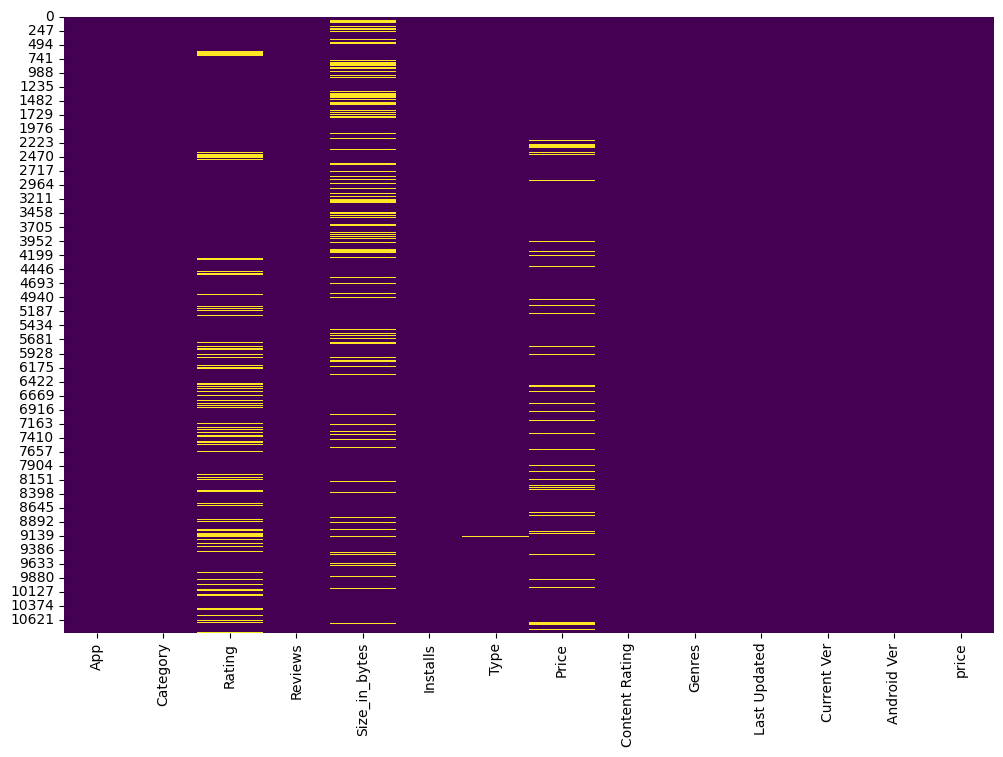

In [204]:
# And this is how i plot the missing values in the dataset
plt.figure(figsize=(12, 8))
sns.heatmap(df.isnull(), cbar=False, cmap='viridis')

Text(0.5, 1.0, 'Percentage of Missing Values in Each Column')

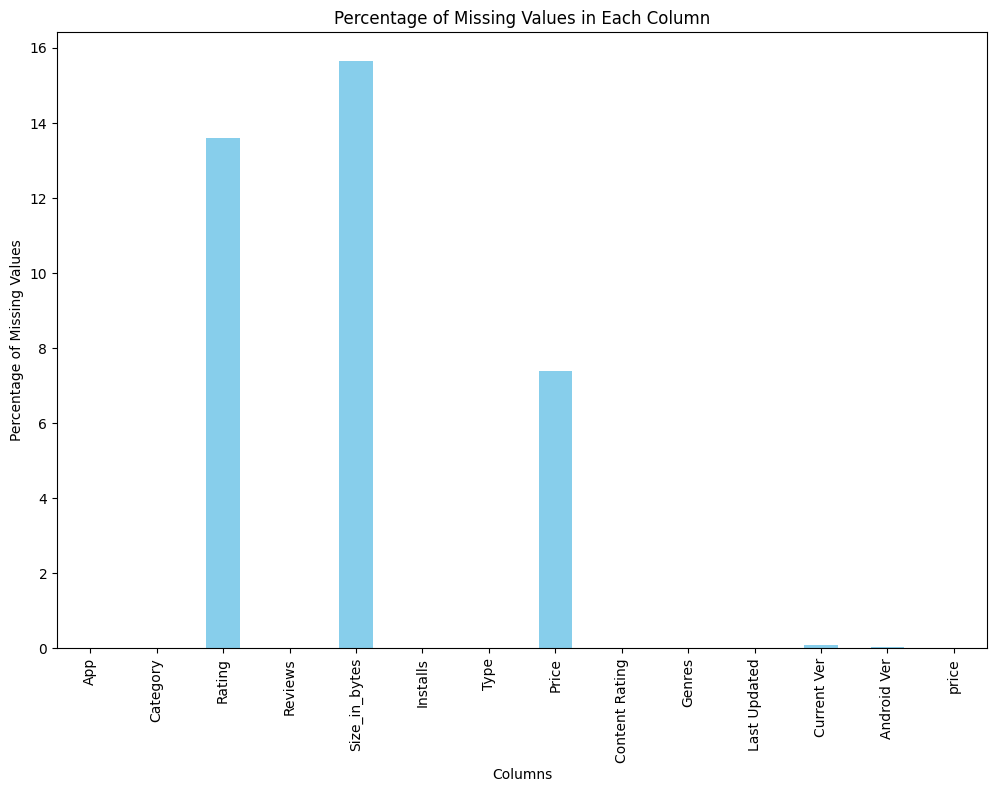

In [205]:
# This is how i can plot the missing value by there percentage in each column of the dataset
# make figure size
plt.figure(figsize=(12, 8))
missing_percentage = df.isnull().sum() / len(df) * 100
missing_percentage.plot(kind='bar', color='skyblue')
# add the labels and title
plt.xlabel('Columns')
plt.ylabel('Percentage of Missing Values')
plt.title('Percentage of Missing Values in Each Column')

In [ ]:
df=pd.read_csv('../data/googleplaystore.csv')
df

In [208]:
df.columns

Index(['App', 'Category', 'Rating', 'Reviews', 'Size', 'Installs', 'Type',
       'Price', 'Content Rating', 'Genres', 'Last Updated', 'Current Ver',
       'Android Ver'],
      dtype='object')

In [ ]:
df.head(10)

In [210]:
df['Installs'].head()

0        10,000+
1       500,000+
2     5,000,000+
3    50,000,000+
4       100,000+
Name: Installs, dtype: object

In [211]:
df['Installs'] = (
    df['Installs']
    .str.replace('+', '', regex=False)
    .str.replace(',', '', regex=False)
)

In [212]:
df['Installs'].head()

0       10000
1      500000
2     5000000
3    50000000
4      100000
Name: Installs, dtype: object

In [217]:
print(df['Installs'].dtype)

object


In [218]:
print(df['Installs'].head(10))

0       10000
1      500000
2     5000000
3    50000000
4      100000
5       50000
6       50000
7     1000000
8     1000000
9       10000
Name: Installs, dtype: object


In [219]:
print(df['Installs'].unique()[:20])

['10000' '500000' '5000000' '50000000' '100000' '50000' '1000000'
 '10000000' '5000' '100000000' '1000000000' '1000' '500000000' '50' '100'
 '500' '10' '1' '5' '0']


In [220]:
df['Installs'].astype(str).str.contains('Free', case=False, na=False).sum()

np.int64(1)

In [221]:
df[df['Installs'].astype(str).str.contains('Free', case=False, na=False)]

,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
10472,Life Made WI-Fi Touchscreen Photo Frame,1.9,19.0,3.0M,"1,000+",Free,0,Everyone,NaN,"February 11, 2018",1.0.19,4.0 and up,NaN


In [222]:
df.loc[10472]

App               Life Made WI-Fi Touchscreen Photo Frame
Category                                              1.9
Rating                                               19.0
Reviews                                              3.0M
Size                                               1,000+
Installs                                             Free
Type                                                    0
Price                                            Everyone
Content Rating                                        NaN
Genres                                  February 11, 2018
Last Updated                                       1.0.19
Current Ver                                    4.0 and up
Android Ver                                           NaN
Name: 10472, dtype: object

In [223]:
df['Installs'].loc[10472]

'Free'

In [224]:
df['Price'].loc[10472]

'Everyone'

In [226]:
df.loc[10472]

App               Life Made WI-Fi Touchscreen Photo Frame
Category                                              1.9
Rating                                               19.0
Reviews                                              3.0M
Size                                               1,000+
Installs                                             Free
Type                                                    0
Price                                            Everyone
Content Rating                                        NaN
Genres                                  February 11, 2018
Last Updated                                       1.0.19
Current Ver                                    4.0 and up
Android Ver                                           NaN
Name: 10472, dtype: object

In [227]:
df.loc[10472, 'Installs'] = '1000'
df.loc[10472, 'Type'] = 'Free'
df.loc[10472, 'Price'] = '0'
df.loc[10472, 'Content Rating'] = 'Everyone'

In [228]:
df['Installs'] = df['Installs'].astype(int)

In [230]:
df['Price'] = df['Price'].str.replace('$', '', regex=False)

In [231]:
df['Price'] = df['Price'].replace('Everyone', '0')

In [232]:
df['Price'] = df['Price'].astype(float)

In [234]:
df['Price'].dtype

dtype('float64')

In [235]:
df[['Installs', 'Price']].dtypes

Installs      int64
Price       float64
dtype: object

In [237]:
df.isnull().sum().sort_values(ascending=False)

Rating            1474
Current Ver          8
Android Ver          3
Type                 1
App                  0
Size                 0
Reviews              0
Category             0
Installs             0
Content Rating       0
Price                0
Last Updated         0
Genres               0
dtype: int64

In [239]:
df.duplicated().sum()

np.int64(483)

In [ ]:
df.info()

In [241]:
df_original = df.copy()

### removing duplicated values

- droping duplicated values in the dataset

In [243]:
df.drop_duplicates(inplace=True)

In [245]:
df.duplicated().sum()

np.int64(0)

In [246]:
len(df)

10358

In [247]:
df[df['Type'].isna()]

,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
9148,Command & Conquer: Rivals,FAMILY,NaN,0,Varies with device,0,NaN,0.0,Everyone 10+,Strategy,"June 28, 2018",Varies with device,Varies with device


In [248]:
df.loc[df['Type'].isna(), 'Type'] = 'Free'

In [249]:
df['Type'].isna().sum()

np.int64(0)

In [ ]:
 # to check the missing values in the current version column
 df[df['Current Ver'].isna()]

,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
15,Learn To Draw Kawaii Characters,ART_AND_DESIGN,3.2,55,2.7M,5000,Free,0.00,Everyone,Art & Design,"June 6, 2018",NaN,4.2 and up
1553,Market Update Helper,LIBRARIES_AND_DEMO,4.1,20145,11k,1000000,Free,0.00,Everyone,Libraries & Demo,"February 12, 2013",NaN,1.5 and up
6322,Virtual DJ Sound Mixer,TOOLS,4.2,4010,8.7M,500000,Free,0.00,Everyone,Tools,"May 10, 2017",NaN,4.0 and up
6803,BT Master,FAMILY,NaN,0,222k,100,Free,0.00,Everyone,Education,"November 6, 2016",NaN,1.6 and up
7333,Dots puzzle,FAMILY,4.0,179,14M,50000,Paid,0.99,Everyone,Puzzle,"April 18, 2018",NaN,4.0 and up
7407,Calculate My IQ,FAMILY,NaN,44,7.2M,10000,Free,0.00,Everyone,Entertainment,"April 3, 2017",NaN,2.3 and up
7730,UFO-CQ,TOOLS,NaN,1,237k,10,Paid,0.99,Everyone,Tools,"July 4, 2016",NaN,2.0 and up
10342,La Fe de Jesus,BOOKS_AND_REFERENCE,NaN,8,658k,1000,Free,0.00,Everyone,Books & Reference,"January 31, 2017",NaN,3.0 and up


In [251]:
df[df['Android Ver'].isna()]

,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
4453,[substratum] Vacuum: P,PERSONALIZATION,4.4,230,11M,1000,Paid,1.49,Everyone,Personalization,"July 20, 2018",4.4,NaN
4490,Pi Dark [substratum],PERSONALIZATION,4.5,189,2.1M,10000,Free,0.00,Everyone,Personalization,"March 27, 2018",1.1,NaN
10472,Life Made WI-Fi Touchscreen Photo Frame,1.9,19.0,3.0M,"1,000+",1000,Free,0.00,Everyone,"February 11, 2018",1.0.19,4.0 and up,NaN


In [252]:
df.loc[df['Android Ver'].isna(), 'Android Ver'] = 'Unknown'

In [253]:
df.loc[10472, 'Android Ver'] = '4.0 and up'

In [254]:
df['Android Ver'].isna().sum()

np.int64(0)

In [255]:
df['Rating'].isna().sum()

np.int64(1465)

In [256]:
df['Rating'].describe()

count    8893.000000
mean        4.189542
std         0.545452
min         1.000000
25%         4.000000
50%         4.300000
75%         4.500000
max        19.000000
Name: Rating, dtype: float64

In [257]:
df[df['Rating'] > 5][['App', 'Rating']]

,App,Rating
10472,Life Made WI-Fi Touchscreen Photo Frame,19.0


In [259]:
df['Rating'] = df['Rating'].fillna(df['Rating'].median())

In [260]:
df['Rating'].isna().sum()

np.int64(0)

In [261]:
df.isna().sum()

App               0
Category          0
Rating            0
Reviews           0
Size              0
Installs          0
Type              0
Price             0
Content Rating    0
Genres            0
Last Updated      0
Current Ver       8
Android Ver       0
dtype: int64

In [263]:
df.dtypes

App                object
Category           object
Rating            float64
Reviews            object
Size               object
Installs            int64
Type               object
Price             float64
Content Rating     object
Genres             object
Last Updated       object
Current Ver        object
Android Ver        object
dtype: object

In [264]:
df[df['Rating'] > 5][['App', 'Rating']]

,App,Rating
10472,Life Made WI-Fi Touchscreen Photo Frame,19.0


In [265]:
df.loc[df['Rating'] > 5, 'Rating'] = np.nan

In [266]:
df['Rating'] = df['Rating'].fillna(df['Rating'].median())

In [267]:
df['Reviews'].head()

0       159
1       967
2     87510
3    215644
4       967
Name: Reviews, dtype: object

In [270]:
df['Reviews'].map(type).value_counts()

Reviews
<class 'str'>    10358
Name: count, dtype: int64

In [271]:
df['Reviews'].unique()[:20]

array(['159', '967', '87510', '215644', '167', '178', '36815', '13791',
       '121', '13880', '8788', '44829', '4326', '1518', '55', '3632',
       '27', '194216', '224399', '450'], dtype=object)

In [272]:
df['Reviews'] = pd.to_numeric(df['Reviews'], errors='coerce')

In [273]:
df['Reviews'].dtype

dtype('float64')

In [274]:
df['Size'].value_counts().head(20)

Size
Varies with device    1526
11M                    188
13M                    186
12M                    186
14M                    182
15M                    174
17M                    155
26M                    145
16M                    143
19M                    135
10M                    133
20M                    131
25M                    131
21M                    130
24M                    129
18M                    124
23M                    109
22M                    108
29M                     95
27M                     94
Name: count, dtype: int64

In [275]:
df['Size'] = df['Size'].replace('Varies with device', np.nan)

In [276]:
def convert_size(x):
    if pd.isna(x):
        return np.nan
    if x.endswith('M'):
        return float(x[:-1])
    elif x.endswith('k'):
        return float(x[:-1]) / 1024
    return np.nan

df['Size'] = df['Size'].apply(convert_size)

In [277]:
df['Size'].head(20)

0     19.0
1     14.0
2      8.7
3     25.0
4      2.8
5      5.6
6     19.0
7     29.0
8     33.0
9      3.1
10    28.0
11    12.0
12    20.0
13    21.0
14    37.0
15     2.7
16     5.5
17    17.0
18    39.0
19    31.0
Name: Size, dtype: float64

In [278]:
df['Size'].dtype

dtype('float64')

In [279]:
df.isna().sum()

App                  0
Category             0
Rating               0
Reviews              1
Size              1527
Installs             0
Type                 0
Price                0
Content Rating       0
Genres               0
Last Updated         0
Current Ver          8
Android Ver          0
dtype: int64

In [280]:
df[['Reviews', 'Size']].isna().sum()

Reviews       1
Size       1527
dtype: int64

In [281]:
df['Reviews'] = df['Reviews'].fillna(df['Reviews'].median())

In [282]:
df[['Reviews', 'Size']].isna().sum()

Reviews       0
Size       1527
dtype: int64

In [283]:
df[df['Rating'] > 5][['App', 'Rating']]

,App,Rating


In [284]:
df[df['Rating'] > 5][['App', 'Rating']]

,App,Rating


In [285]:
df['Rating'].max()

np.float64(5.0)

In [286]:
df['Rating'].isna().sum()

np.int64(0)

In [287]:
df.isnull().sum()

App                  0
Category             0
Rating               0
Reviews              0
Size              1527
Installs             0
Type                 0
Price                0
Content Rating       0
Genres               0
Last Updated         0
Current Ver          8
Android Ver          0
dtype: int64

In [288]:
df.dtypes

App                object
Category           object
Rating            float64
Reviews           float64
Size              float64
Installs            int64
Type               object
Price             float64
Content Rating     object
Genres             object
Last Updated       object
Current Ver        object
Android Ver        object
dtype: object

In [290]:
df['Reviewes']=df['Reviews'].astype(int)

In [291]:
df.dtypes

App                object
Category           object
Rating            float64
Reviews           float64
Size              float64
Installs            int64
Type               object
Price             float64
Content Rating     object
Genres             object
Last Updated       object
Current Ver        object
Android Ver        object
Reviewes            int64
dtype: object

In [292]:
df.duplicated().sum()

np.int64(0)

# Starting EDA

In [293]:
df.describe()

,Rating,Reviews,Size,Installs,Price,Reviewes
count,10358.000000,1.035800e+04,8831.000000,1.035800e+04,10358.000000,1.035800e+04
mean,4.203746,4.058656e+05,21.287413,1.415639e+07,1.030701,4.058656e+05
std,0.485572,2.696651e+06,22.540591,8.023580e+07,16.277843,2.696651e+06
min,1.000000,0.000000e+00,0.008301,0.000000e+00,0.000000,0.000000e+00
25%,4.100000,3.200000e+01,4.700000,1.000000e+03,0.000000,3.200000e+01
50%,4.300000,1.680000e+03,13.000000,1.000000e+05,0.000000,1.680000e+03
75%,4.500000,4.640425e+04,29.000000,1.000000e+06,0.000000,4.640425e+04
max,5.000000,7.815831e+07,100.000000,1.000000e+09,400.000000,7.815831e+07


In [294]:
df.drop(columns=['Reviewes'], inplace=True)

In [ ]:
df[]

Index(['App', 'Category', 'Rating', 'Reviews', 'Size', 'Installs', 'Type',
       'Price', 'Content Rating', 'Genres', 'Last Updated', 'Current Ver',
       'Android Ver'],
      dtype='object')